## Step 1 — Load and clean the dataset

In [3]:
import pandas as pd

# Load original dataset
df = pd.read_csv("../data/raw/creditcard.csv")

# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Check dataset information
print("Original transactions:", len(df))
print("Duplicates removed:", len(df) - len(df_clean))
print("Cleaned transactions:", len(df_clean))

print("\nClass distribution:")
print(df_clean["Class"].value_counts())

Original transactions: 284807
Duplicates removed: 1081
Cleaned transactions: 283726

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


## Step 2 — Separate Features (X) and Target (y)

In [4]:

# Separate input features and target
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNumber of input features:", X.shape[1])
print("Normal transactions:", (y == 0).sum())
print("Fraud transactions:", (y == 1).sum())


X shape: (283726, 30)
y shape: (283726,)

Number of input features: 30
Normal transactions: 283253
Fraud transactions: 473


## Step 3 — Split Data into Training, Validation, and Test Sets

In [5]:

from sklearn.model_selection import train_test_split

# First split 80% training, 20% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split 10% validation, 10% test data
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, "--> Fraud:", y_train.sum())
print("Validation:", X_val.shape, "--> Fraud:", y_val.sum())
print("Test:", X_test.shape, "--------> Fraud:", y_test.sum())


Training: (226980, 30) --> Fraud: 378
Validation: (28373, 30) --> Fraud: 48
Test: (28373, 30) --------> Fraud: 47


## Step 4 — Feature Standardization (StandardScaler)

In [6]:

from sklearn.preprocessing import StandardScaler

# Create  scaler
scaler = StandardScaler()

# Learn mean and standard deviation from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply  same transformation to validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training:", X_train_scaled.shape)
print("_________________________________")
print("Validation:", X_val_scaled.shape)
print("_________________________________")
print("Test:", X_test_scaled.shape)
print("_________________________________")



Training: (226980, 30)
_________________________________
Validation: (28373, 30)
_________________________________
Test: (28373, 30)
_________________________________


## Step 5 — Train Class-Weighted Logistic Regression

In [7]:

from sklearn.linear_model import LogisticRegression

#  Class-Weighted Logistic Regression
weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train using only the training dataset
weighted_model.fit(X_train_scaled, y_train)

#print("Class Weighted Logistic Regression trained")

print("Classes:", weighted_model.classes_)
print("Training transactions:", len(y_train))
print("Fraud cases in training:", y_train.sum())


Classes: [0 1]
Training transactions: 226980
Fraud cases in training: 378


In [8]:
'''
import time

# Start timing
start_time = time.perf_counter()

# Train the weighted model again to measure its speed
weighted_model.fit(X_train_scaled, y_train)

# Stop timing
training_time = time.perf_counter() - start_time

print("Class-Weighted Logistic Regression")
print("-" * 40)
print(f"Training time: {training_time:.3f} seconds")
print(f"Optimizer iterations: {weighted_model.n_iter_[0]}")
print(f"Maximum allowed iterations: {weighted_model.max_iter}")
print(f"Training samples: {len(y_train):,}")


'''

'\nimport time\n\n# Start timing\nstart_time = time.perf_counter()\n\n# Train the weighted model again to measure its speed\nweighted_model.fit(X_train_scaled, y_train)\n\n# Stop timing\ntraining_time = time.perf_counter() - start_time\n\nprint("Class-Weighted Logistic Regression")\nprint("-" * 40)\nprint(f"Training time: {training_time:.3f} seconds")\nprint(f"Optimizer iterations: {weighted_model.n_iter_[0]}")\nprint(f"Maximum allowed iterations: {weighted_model.max_iter}")\nprint(f"Training samples: {len(y_train):,}")\n\n\n'

## Step 6 — Validation Confusion Matrix (Threshold = 0.50)

CLASS-WEIGHTED LOGISTIC REGRESSION
Validation Set | Threshold = 0.50
----------------------------------------
TP - Fraud detected: 40
FN - Fraud missed:   8
FP - False alarms:   661
TN - Normal correct: 27664

Precision: 0.0571
Recall:    0.8333
F1-score:  0.1068


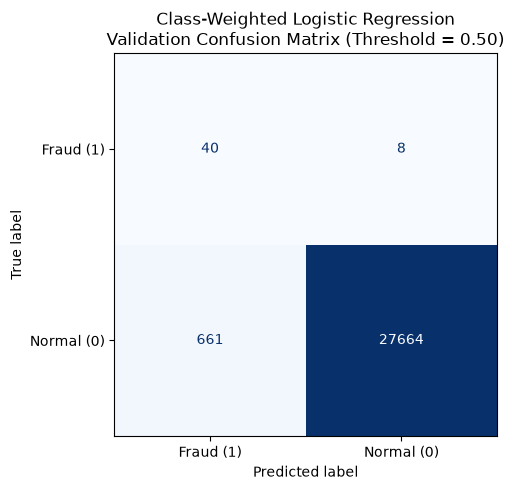

In [9]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt

# Predict fraud probabilities on validation data
y_val_proba = weighted_model.predict_proba(X_val_scaled)[:, 1]

# Use the default threshold of 0.50
threshold = 0.50
y_val_pred = (y_val_proba >= threshold).astype(int)

# Fraud-first confusion matrix: TP, FN / FP, TN
cm = confusion_matrix(y_val, y_val_pred, labels=[1, 0])

TP, FN = cm[0]
FP, TN = cm[1]

print("CLASS-WEIGHTED LOGISTIC REGRESSION")
print("Validation Set | Threshold = 0.50")
print("-" * 40)

print(f"TP - Fraud detected: {TP}")
print(f"FN - Fraud missed:   {FN}")
print(f"FP - False alarms:   {FP}")
print(f"TN - Normal correct: {TN}")

print(f"\nPrecision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred):.4f}")

# Plot confusion matrix with Fraud first
fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fraud (1)", "Normal (0)"]
)

disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title(
    "Class-Weighted Logistic Regression\n"
    "Validation Confusion Matrix (Threshold = 0.50)"
)

plt.tight_layout()
plt.show()


#### Can we increase the weighted model's decision threshold to reduce false alarms hile still detecting more fraud than Standard Logistic Regression?/


### Step 7 — Decision Threshold Analysis (Weighted Logistic Regression)

,Threshold,TP,FN,FP,Precision,Recall,F1
0,0.50,40,8,661,0.0571,0.8333,0.1068
1,0.70,40,8,307,0.1153,0.8333,0.2025
2,0.80,38,10,196,0.1624,0.7917,0.2695
3,0.90,37,11,108,0.2552,0.7708,0.3834
4,0.95,36,12,49,0.4235,0.7500,0.5414
5,0.97,36,12,36,0.5000,0.7500,0.6000
6,0.99,36,12,19,0.6545,0.7500,0.6990



Best tested threshold by validation F1: 0.99


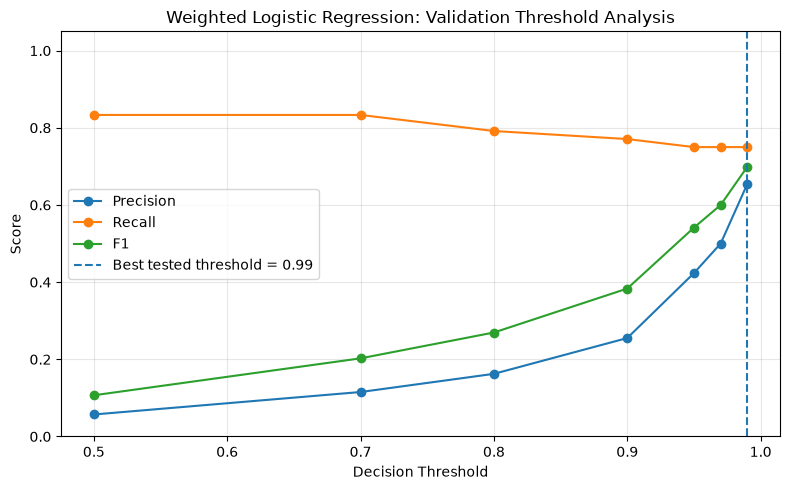

In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Test different decision thresholds
thresholds = [0.50, 0.70, 0.80, 0.90, 0.95, 0.97, 0.99]

results = []

for t in thresholds:
    predictions = (y_val_proba >= t).astype(int)

    # Fraud-first confusion matrix
    cm = confusion_matrix(y_val, predictions, labels=[1, 0])
    TP, FN = cm[0]
    FP, TN = cm[1]

    results.append({
        "Threshold": t,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0)
    })

weighted_threshold_results = pd.DataFrame(results)


display(weighted_threshold_results.round(4))

# Select highest validation F1 among tested thresholds
best_idx = weighted_threshold_results["F1"].idxmax()
weighted_best_threshold = float(
    weighted_threshold_results.loc[best_idx, "Threshold"]
)

print(f"\nBest tested threshold by validation F1: {weighted_best_threshold:.2f}")

# Visualize precision, recall and F1
plt.figure(figsize=(8, 5))

for metric in ["Precision", "Recall", "F1"]:
    plt.plot(
        weighted_threshold_results["Threshold"],
        weighted_threshold_results[metric],
        marker="o",
        label=metric
    )

plt.axvline(
    weighted_best_threshold,
    linestyle="--",
    label=f"Best tested threshold = {weighted_best_threshold:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Weighted Logistic Regression: Validation Threshold Analysis")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
